In [22]:
print("Feature Engineering Pipeline Started!")
print("Python is working correctly.")

Feature Engineering Pipeline Started!
Python is working correctly.


In [23]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [24]:
df = pd.read_csv("customer-churn-training.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (12, 7)


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


In [25]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Column names:
['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']

Data types:
customer_id            str
tenure_months        int64
support_tickets      int64
monthly_spend_inr    int64
last_login_days      int64
plan_type              str
churned              int64
dtype: object

Missing values:
customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate rows:
0


In [26]:
from sklearn.model_selection import train_test_split

print("Train-test splitting tools imported successfully!")

Train-test splitting tools imported successfully!


In [27]:
# Separate input features and target

X = df.drop(columns=["churned", "customer_id"])
y = df["churned"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Input features:
['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type']

Target:
churned


In [28]:
['tenure_months', 'support_tickets',
 'monthly_spend_inr', 'last_login_days', 'plan_type']

['tenure_months',
 'support_tickets',
 'monthly_spend_inr',
 'last_login_days',
 'plan_type']

In [29]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']

Categorical features:
['plan_type']


C:\Users\Chandan sai\AppData\Local\Temp\ipykernel_13428\1390013320.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [30]:
# Split the dataset before preprocessing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (9, 5)
Testing data shape: (3, 5)

Training target distribution:
churned
0    5
1    4
Name: count, dtype: int64

Testing target distribution:
churned
0    2
1    1
Name: count, dtype: int64


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [32]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created!")

Numerical preprocessing pipeline created!


In [33]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created!")

Categorical preprocessing pipeline created!


In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [35]:
# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (9, 7)
Testing data after preprocessing: (3, 7)


In [36]:
print("Original training columns:")
print(X_train.columns.tolist())

print("\nTransformed training shape:")
print(X_train_processed.shape)

print("\nTransformed testing shape:")
print(X_test_processed.shape)

print("\nPreprocessing pipeline:")
print(preprocessor)

Original training columns:
['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type']

Transformed training shape:
(9, 7)

Transformed testing shape:
(3, 7)

Preprocessing pipeline:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure_months', 'support_tickets',
                                  'monthly_spend_inr', 'last_login_days']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                           

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical input features and the target
correlation_data = df[
    numerical_features + ["churned"]
]

# Calculate correlations
correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
tenure_months,1.000000,-0.893032,0.868524,-0.826201,-0.760880
support_tickets,-0.893032,1.000000,-0.793155,0.941775,0.853786
monthly_spend_inr,0.868524,-0.793155,1.000000,-0.817452,-0.787426
last_login_days,-0.826201,0.941775,-0.817452,1.000000,0.854060
churned,-0.760880,0.853786,-0.787426,0.854060,1.000000


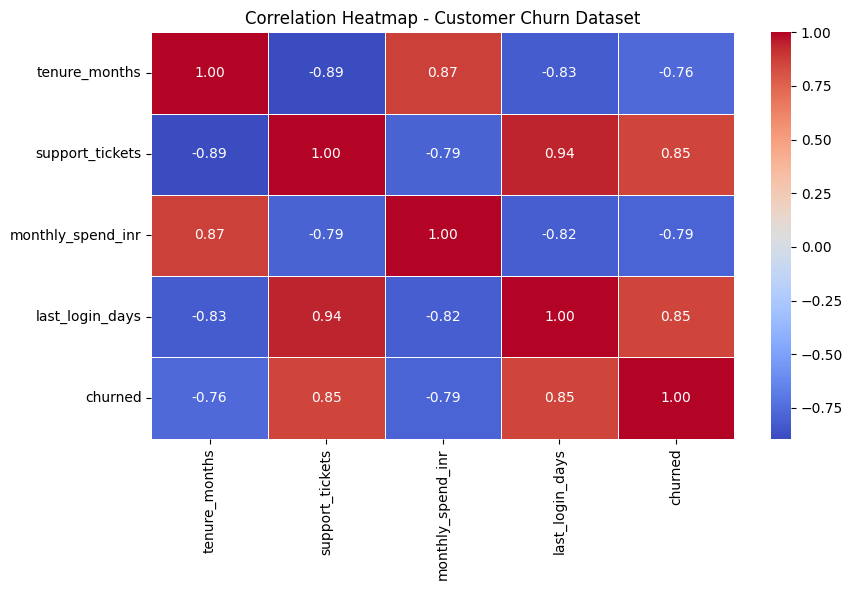

In [38]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Customer Churn Dataset")
plt.tight_layout()
plt.show()

In [39]:
from sklearn.feature_selection import mutual_info_classif

print("Mutual Information tools imported successfully!")

Mutual Information tools imported successfully!


In [40]:
# Transform training data using the fitted preprocessor
X_train_transformed = preprocessor.transform(X_train)

# Obtain the names of transformed features
feature_names = preprocessor.get_feature_names_out()

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_array = X_train_transformed.toarray()
else:
    X_train_array = X_train_transformed

# Calculate Mutual Information scores
mi_scores = mutual_info_classif(
    X_train_array,
    y_train,
    random_state=42
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mutual_Information": mi_scores
})

importance_df = importance_df.sort_values(
    by="Mutual_Information",
    ascending=False
)

display(importance_df)

,Feature,Mutual_Information
4,cat__plan_type_Basic,1.412302
0,num__tenure_months,0.643783
3,num__last_login_days,0.587169
1,num__support_tickets,0.469709
2,num__monthly_spend_inr,0.464153
6,cat__plan_type_Standard,0.095635
5,cat__plan_type_Pro,0.014153


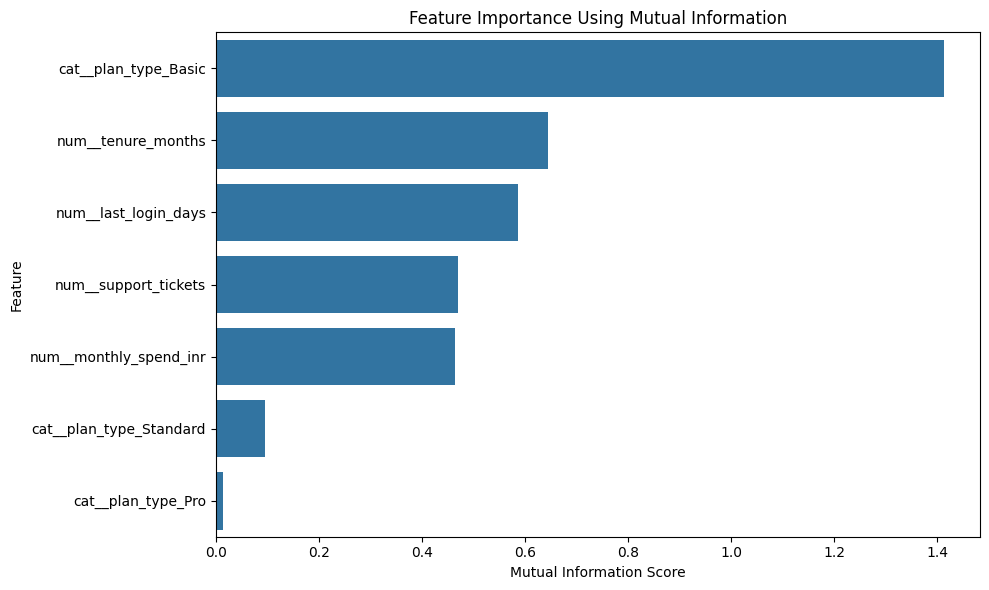

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Mutual_Information",
    y="Feature"
)

plt.title("Feature Importance Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a complete pipeline
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using training data
model_pipeline.fit(X_train, y_train)

# Predict outcomes for test data
y_pred = model_pipeline.predict(X_test)

# Evaluate the model
print("Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3


Confusion Matrix:
[[2 0]
 [0 1]]


## Conclusion

In this project, a reusable feature engineering and preprocessing pipeline was developed using Python and Scikit-Learn. The dataset was loaded and inspected for missing values, data types, and duplicate records. The data was split into training and testing sets before preprocessing to reduce the risk of data leakage.

A ColumnTransformer was used to process numerical and categorical features. Numerical features were imputed using the median and scaled using StandardScaler, while categorical features were imputed using the most frequent value and encoded using OneHotEncoder.

Correlation analysis was performed to examine relationships between numerical features and the target variable. Mutual information was used to estimate feature importance. A complete Scikit-Learn Pipeline combining preprocessing and Logistic Regression was then trained and evaluated.

The model achieved 100% accuracy on the three test samples. However, the dataset is very small, so this result should not be interpreted as evidence of reliable real-world performance. Further testing on a larger, representative dataset is necessary.

In [43]:
# Step 1: Check dataset size and target distribution

print("Dataset shape:", df.shape)

print("\nTarget class distribution:")
print(y.value_counts())

print("\nTarget class percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nTraining set size:", len(X_train))
print("Testing set size:", len(X_test))

Dataset shape: (12, 7)

Target class distribution:
churned
0    7
1    5
Name: count, dtype: int64

Target class percentages:
churned
0    58.33
1    41.67
Name: proportion, dtype: float64

Training set size: 9
Testing set size: 3


In [44]:
# Step 3: Train and compare four baseline models

import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define four models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "SVM": SVC(
        probability=True, random_state=42
    )
}

results = []
trained_models = {}

for name, classifier in models.items():

    # Clone the preprocessing pipeline so each model
    # gets its own independent fitted preprocessor
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    # Train on the training set
    pipeline.fit(X_train, y_train)

    # Predict test labels
    predictions = pipeline.predict(X_test)

    # Predict probabilities for ROC-AUC
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Collect evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_test, probabilities)
            if len(set(y_test)) == 2
            else float("nan")
        )
    })

    trained_models[name] = pipeline

# Display the comparison table
comparison_df = pd.DataFrame(results)

display(
    comparison_df.round(3).sort_values(
        by="F1-Score", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,SVM,1.0,1.0,1.0,1.0,1.0


In [45]:
# Step 4: Hyperparameter tuning using GridSearchCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define hyperparameter grids
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "classifier__max_depth": [2, 3, None],
        "classifier__min_samples_split": [2, 3]
    },
    "Random Forest": {
        "classifier__n_estimators": [50, 100],
        "classifier__max_depth": [2, 3, None]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"]
    }
}

tuning_results = []
best_models = {}

for name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1-Score": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(3))

,Model,Best CV F1-Score,Best Parameters
0,Logistic Regression,1.0,{'classifier__C': 1}
1,Decision Tree,1.0,"{'classifier__max_depth': 2, 'classifier__min_..."
2,Random Forest,1.0,"{'classifier__max_depth': 2, 'classifier__n_es..."
3,SVM,1.0,"{'classifier__C': 0.1, 'classifier__kernel': '..."


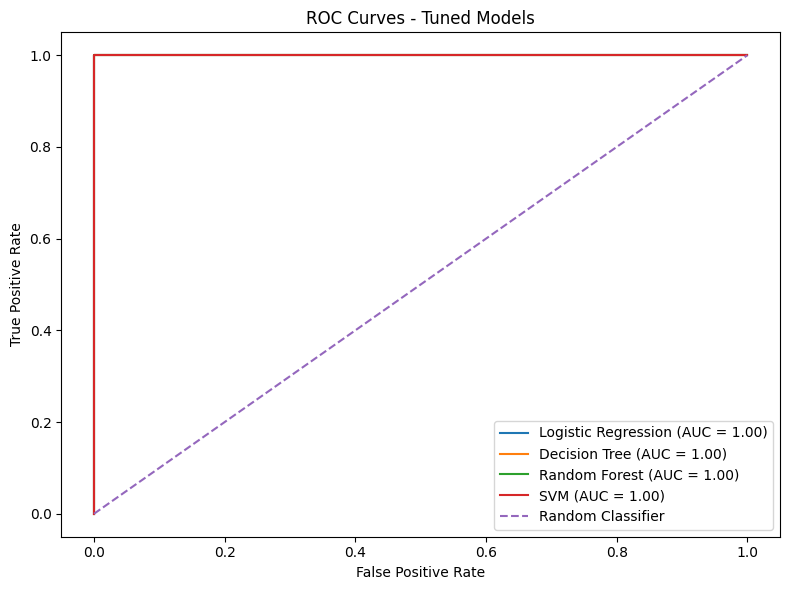

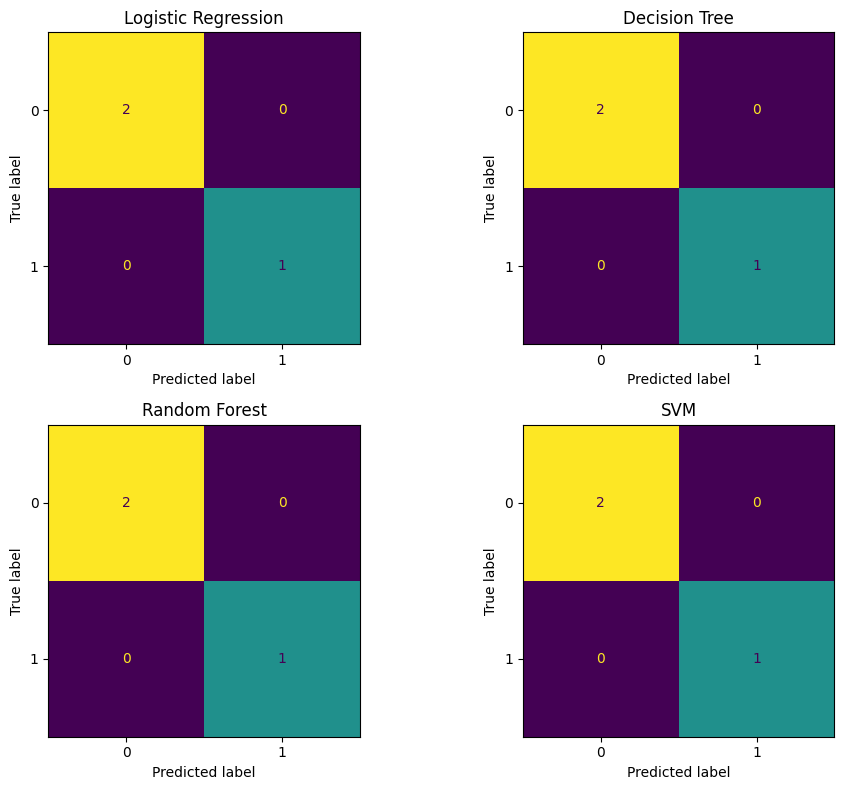

In [46]:
# Step 5: ROC curves and confusion matrices

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for name, model in best_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Tuned Models")
plt.legend()
plt.tight_layout()
plt.show()


# Plot confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, (name, model) in zip(axes, best_models.items()):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[0, 1]
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [47]:
# Step 6: Save the selected model

import joblib
from pathlib import Path

# Select Logistic Regression for this demonstration
champion_model = best_models["Logistic Regression"]

# Save the complete pipeline, including preprocessing
model_path = Path("champion_churn_model.joblib")

joblib.dump(champion_model, model_path)

print("Champion model saved successfully!")
print("Model name: Logistic Regression")
print("Saved file:", model_path.resolve())

Champion model saved successfully!
Model name: Logistic Regression
Saved file: C:\Users\Chandan sai\Downloads\Feature_Engineering_Pipeline\champion_churn_model.joblib
